# RQ1 – Delivery Performance and Customer Satisfaction

## Research question
Does late delivery negatively affect customer satisfaction in the Olist e-commerce marketplace?

## Hypotheses

**Null hypothesis (H0):** There is no statistically significant difference in customer review scores between late deliveries and on-time or early deliveries.

**Alternative hypothesis (H1):** There is a statistically significant difference in customer review scores between late deliveries and on-time or early deliveries.

## Methodology

- Data source: Olist order-level customer satisfaction view in PostgreSQL.
- Eligible population: Delivered orders with valid chronology and an available review score.
- Independent variable: Delivery performance (late vs. on time or early).
- Dependent variable: Average customer review score.
- Statistical test: Two-sided Mann–Whitney U test.
- Significance level: 0.05.

In [1]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from scipy.stats import mannwhitneyu

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

# Visualisation settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
%pip install "psycopg[binary]"

  Using cached psycopg-3.3.8-py3-none-any.whl.metadata (4.4 kB)
  Using cached psycopg_binary-3.3.8-cp314-cp314-macosx_11_0_arm64.whl.metadata (2.7 kB)
Using cached psycopg-3.3.8-py3-none-any.whl (216 kB)
Using cached psycopg_binary-3.3.8-cp314-cp314-macosx_11_0_arm64.whl (4.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [psycopg]m1/2 [psycopg]
Note: you may need to restart the kernel to use updated packages.


In [4]:
import psycopg

print("Psycopg version:", psycopg.__version__)
print("Psycopg installed successfully!")

Psycopg version: 3.3.8
Psycopg installed successfully!


In [5]:
# Load database credentials from the .env file
load_dotenv()

# Check that all required variables are available
required_variables = [
    "DB_USER",
    "DB_PASSWORD",
    "DB_HOST",
    "DB_PORT",
    "DB_NAME"
]

missing_variables = [
    variable for variable in required_variables
    if not os.getenv(variable)
]

if missing_variables:
    raise ValueError(
        f"Missing environment variables: {missing_variables}"
    )

# Database schema
schema = os.getenv("DB_SCHEMA", "s_atikesanli")

# Validate schema name
if not re.fullmatch(r"[A-Za-z_][A-Za-z0-9_]*", schema):
    raise ValueError("Invalid database schema name.")

# Create database connection
connection_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME")
)

engine = create_engine(
    connection_url,
    connect_args={
        "options": "-c default_transaction_read_only=on"
    }
)

# Test connection
with engine.connect() as connection:
    database_info = connection.execute(
        text("""
            SELECT
                current_database() AS database_name,
                current_user AS database_user,
                version() AS postgresql_version
        """)
    ).fetchone()

print("PostgreSQL connection successful!")
print("Database:", database_info.database_name)
print("User:", database_info.database_user)
print("Schema:", schema)
print("Version:", database_info.postgresql_version)

PostgreSQL connection successful!
Database: nf_da_onl_en_200726
User: atikesanli
Schema: s_atikesanli
Version: PostgreSQL 17.9 on x86_64-pc-linux-gnu, compiled by x86_64-pc-linux-gnu-gcc (GCC) 12.4.0, 64-bit


In [6]:
query_rq1 = text(f"""
    SELECT
        order_id,
        delivery_performance,
        chronology_status,
        average_review_score
    FROM {schema}.int_order_customer_satisfaction
    WHERE order_status = 'delivered'
      AND chronology_status = 'Valid chronology'
      AND delivery_performance IN ('Late', 'On time or early')
      AND average_review_score IS NOT NULL
""")

with engine.connect() as connection:
    df_rq1 = pd.read_sql_query(query_rq1, connection)

print("RQ1 dataset successfully retrieved!")
print("Number of observations:", len(df_rq1))

display(df_rq1.head(10))

RQ1 dataset successfully retrieved!
Number of observations: 95178


,order_id,delivery_performance,chronology_status,average_review_score
0,9b6c23f7e50fe64b97022b8c0d3602a6,On time or early,Valid chronology,5.000
1,a7ba0112ae1019055442b330ee484e67,On time or early,Valid chronology,5.000
2,f6e13cf914f6c5fdcbd6100c8bcdb389,On time or early,Valid chronology,5.000
3,2889a938b438bbaf4701f63a2545bb3b,On time or early,Valid chronology,5.000
4,ed273cdf7e2668c17d6cb199ad52d7c4,On time or early,Valid chronology,5.000
5,06ad94997dd34a7c2186b82d8e9be6a5,On time or early,Valid chronology,5.000
6,51122623ee1ccdaadbb6fcd95f077d8a,On time or early,Valid chronology,5.000
7,639b603f09b7050c96e56cd03703437b,On time or early,Valid chronology,5.000
8,c0b4d042df532a3a84b95e89bf2a53c1,On time or early,Valid chronology,4.000
9,aadd7193594d4613a0aa92401c30234b,On time or early,Valid chronology,5.000


In [7]:
# Check dataset structure
print("Dataset dimensions:", df_rq1.shape)
print("\nColumn information:")
df_rq1.info()

# Check missing values
print("\nMissing values:")
display(df_rq1.isnull().sum().to_frame("Missing values"))

# Check duplicate orders
print("\nDuplicate order IDs:", df_rq1["order_id"].duplicated().sum())

# Check delivery performance groups
print("\nDelivery performance counts:")
display(df_rq1["delivery_performance"].value_counts().to_frame("Number of orders"))

# Check unique delivery categories
print("\nDelivery performance categories:")
print(df_rq1["delivery_performance"].unique())

Dataset dimensions: (95178, 4)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 95178 entries, 0 to 95177
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   order_id              95178 non-null  str    
 1   delivery_performance  95178 non-null  str    
 2   chronology_status     95178 non-null  str    
 3   average_review_score  95178 non-null  float64
dtypes: float64(1), str(3)
memory usage: 2.9 MB

Missing values:


,Missing values
order_id,0
delivery_performance,0
chronology_status,0
average_review_score,0



Duplicate order IDs: 0

Delivery performance counts:


,Number of orders
delivery_performance,
On time or early,87569
Late,7609



Delivery performance categories:
<StringArray>
['On time or early', 'Late']
Length: 2, dtype: str


In [8]:
# Descriptive statistics by delivery performance
rq1_summary = (
    df_rq1
    .groupby("delivery_performance")["average_review_score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        standard_deviation="std",
        minimum="min",
        maximum="max"
    )
    .round(3)
)

display(rq1_summary)

,count,mean,median,standard_deviation,minimum,maximum
delivery_performance,,,,,,
Late,7609,2.566,2.000,1.658,1.000,5.000
On time or early,87569,4.296,5.000,1.144,1.000,5.000


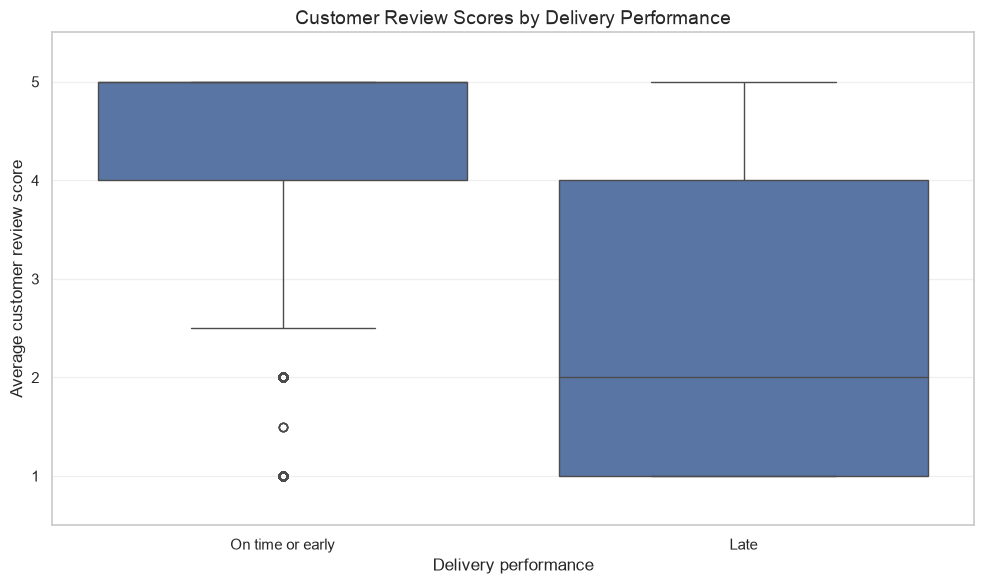

In [10]:
from pathlib import Path

# Create output folder
Path("../figures").mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_rq1,
    x="delivery_performance",
    y="average_review_score",
    order=["On time or early", "Late"]
)

plt.title(
    "Customer Review Scores by Delivery Performance",
    fontsize=14
)
plt.xlabel("Delivery performance")
plt.ylabel("Average customer review score")
plt.ylim(0.5, 5.5)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figures/rq1_review_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Separate the two groups
late = df_rq1.loc[
    df_rq1["delivery_performance"] == "Late",
    "average_review_score"
]

on_time = df_rq1.loc[
    df_rq1["delivery_performance"] == "On time or early",
    "average_review_score"
]

# Perform two-sided Mann–Whitney U test
result = mannwhitneyu(
    late,
    on_time,
    alternative="two-sided",
    method="asymptotic"
)

# Calculate rank-biserial correlation
n_late = len(late)
n_on_time = len(on_time)

rank_biserial = (
    2 * result.statistic / (n_late * n_on_time)
) - 1

# Display results
print("MANN–WHITNEY U TEST – RQ1")
print("-" * 45)

print(f"Late delivery sample size: {n_late:,}")
print(f"On-time/early sample size: {n_on_time:,}")

print(f"\nU statistic: {result.statistic:,.2f}")
print(f"P-value: {result.pvalue:.10g}")
print(f"Rank-biserial correlation: {rank_biserial:.4f}")

if result.pvalue < 0.05:
    print("\nResult: Statistically significant difference.")
else:
    print("\nResult: No statistically significant difference.")

MANN–WHITNEY U TEST – RQ1
---------------------------------------------
Late delivery sample size: 7,609
On-time/early sample size: 87,569

U statistic: 148,395,758.00
P-value: 0
Rank-biserial correlation: -0.5546

Result: Statistically significant difference.


## RQ1 – Results and interpretation

A Mann–Whitney U test was conducted to examine whether customer review scores differed between late deliveries and deliveries completed on time or early.

The analysis included 95,178 delivered orders with valid delivery chronology and an available customer review score. Of these, 7,609 orders were delivered late, while 87,569 were delivered on time or early.

The descriptive results showed that late deliveries received a substantially lower average review score (M = 2.57) than on-time or early deliveries (M = 4.30). The median review score was also lower for late deliveries (2) than for on-time or early deliveries (5).

The Mann–Whitney U test identified a statistically significant difference between the two groups (U = 148,395,758, p < .001). The rank-biserial correlation was −0.5546, indicating a sizeable difference in the distributions, with lower review scores generally associated with late deliveries.

Therefore, the null hypothesis is rejected, and the alternative hypothesis is supported.

These findings suggest a strong association between delivery performance and customer satisfaction. However, because this is an observational analysis, the results do not establish that late delivery alone causes lower customer satisfaction.

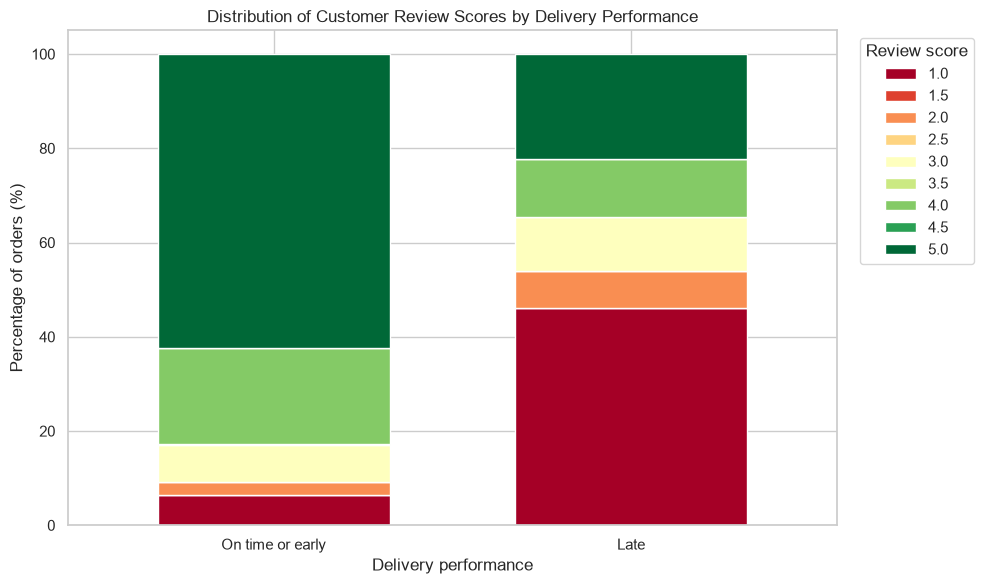

average_review_score,1.000,1.500,2.000,2.500,3.000,3.500,4.000,4.500,5.000
delivery_performance,,,,,,,,,
On time or early,6.520,0.000,2.620,0.010,7.980,0.010,20.370,0.020,62.460
Late,46.160,0.010,7.850,0.030,11.410,0.010,12.310,0.010,22.210


In [13]:
# Calculate percentage distribution of review scores
score_distribution = pd.crosstab(
    df_rq1["delivery_performance"],
    df_rq1["average_review_score"],
    normalize="index"
) * 100

score_distribution = score_distribution.reindex(
    ["On time or early", "Late"]
)

# Plot
ax = score_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    colormap="RdYlGn",
    width=0.65
)

plt.title(
    "Distribution of Customer Review Scores by Delivery Performance"
)
plt.xlabel("Delivery performance")
plt.ylabel("Percentage of orders (%)")
plt.legend(title="Review score", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../figures/rq1_review_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(score_distribution.round(2))